In [1]:
   import openpyxl


In [2]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LinearRegression
age = [18, 18, 18, 20, 20, 25, 25, 30, 30, 30, 35, 35, 40, 40, 45, 50, 55, 55, 60, 60, 65]
revenu = [2000, 1500, 2300, 2500, 2700, 2900, 3400, 3600, 4400, 4100, 4500, 5000, 5100, 5700, 5900, 6500, 6800, 7300, 7800, 8000, 8500]



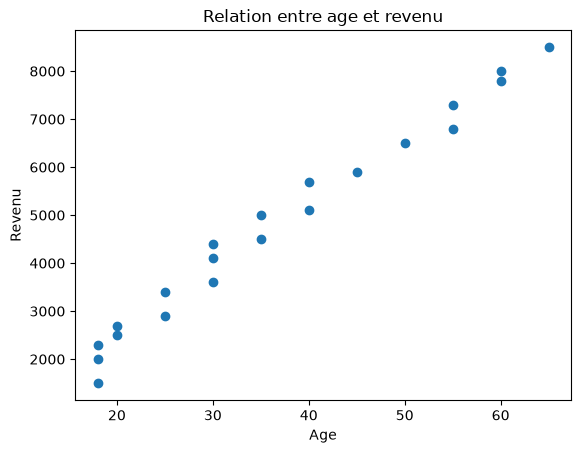

In [3]:
plt.scatter(age, revenu)
plt.xlabel('Age')
plt.ylabel('Revenu')
plt.title('Relation entre age et revenu')
plt.show()

In [4]:
X = np.array(age).reshape(-1, 1)
y = np.array(revenu)
modele = LinearRegression()
modele.fit(X, y)
y_pred = modele.predict(X)

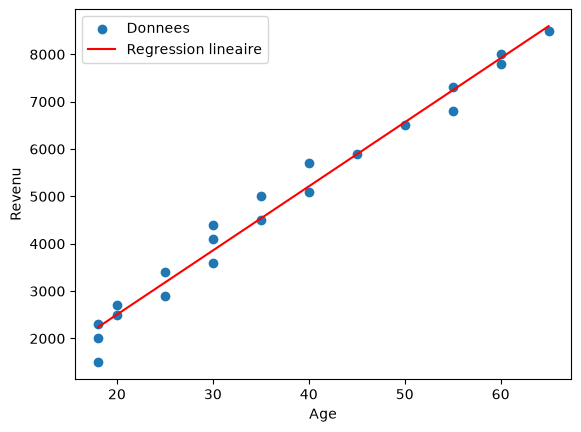

In [5]:
plt.scatter(X, y, label='Donnees')
plt.plot(X.ravel(), y_pred, color='red', label='Regression lineaire')
plt.xlabel('Age'); plt.ylabel('Revenu')
plt.legend(); plt.show()

In [6]:
print('Intercept :', modele.intercept_)
print('Pente :', modele.coef_[0])
print('R² :', modele.score(X, y))
print('Revenu estime a 54 ans :', modele.predict([[54]])[0])

Intercept : -203.23779193206155
Pente : 135.3591648973815
R² : 0.9792270923350723
Revenu estime a 54 ans : 7106.15711252654


In [7]:
#Activite 2
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
df = pd.read_csv('day.csv')
print('Dimensions:', df.shape)
display(df.head())
df.info()
print(df.isna().sum())
display(df.describe())

Dimensions: (731, 16)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    str    
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), str(1)
memory usage: 98.6 KB
instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday     

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


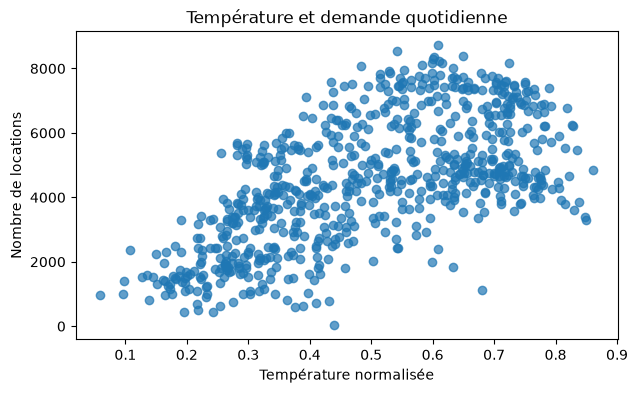

In [8]:
plt.figure(figsize=(7, 4))
plt.scatter(df['temp'], df['cnt'], alpha=0.7)
plt.xlabel('Température normalisée'); plt.ylabel('Nombre de locations')
plt.title('Température et demande quotidienne')
plt.show()

In [9]:
X_all = df[['temp', 'hum', 'windspeed']]
y = df['cnt']

X_train, X_test, y_train, y_test = train_test_split(
    X_all, y, test_size=0.2, random_state=42)

modele_simple = LinearRegression()
modele_simple.fit(X_train[['temp']], y_train)
y_pred_simple = modele_simple.predict(X_test[['temp']])

In [10]:
mse_simple = mean_squared_error(y_test, y_pred_simple)
r2_simple = r2_score(y_test, y_pred_simple)
print('MSE - modèle simple :', mse_simple)
print('R² - modèle simple :', r2_simple)

MSE - modèle simple : 2391051.8856316973
R² - modèle simple : 0.40371020554910975


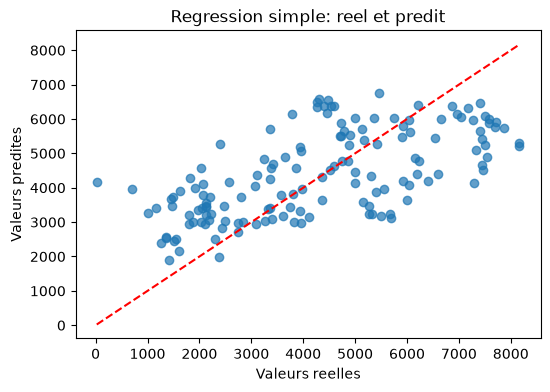

In [11]:
plt.figure(figsize=(6, 4))
plt.scatter(y_test, y_pred_simple, alpha=0.7)
lim_min = min(y_test.min(), y_pred_simple.min())
lim_max = max(y_test.max(), y_pred_simple.max())
plt.plot([lim_min, lim_max], [lim_min, lim_max], 'r--')
plt.xlabel('Valeurs reelles'); plt.ylabel('Valeurs predites')
plt.title('Regression simple: reel et predit')
plt.show()

In [12]:
X_train_multi = X_train[['temp', 'hum', 'windspeed']]
X_test_multi = X_test[['temp', 'hum', 'windspeed']]

modele_multiple = LinearRegression()
modele_multiple.fit(X_train_multi, y_train)
y_pred_multi = modele_multiple.predict(X_test_multi)

mse_multi = mean_squared_error(y_test, y_pred_multi)
r2_multi = r2_score(y_test, y_pred_multi)
print('MSE - modele multiple:', mse_multi)
print('R² - modele multiple:', r2_multi)

MSE - modele multiple: 2020722.2320442523
R² - modele multiple: 0.49606445111931274


In [13]:
comparaison = pd.DataFrame({
    'Modele': ['Regression simple', 'Regression multiple'],
    'MSE': [mse_simple, mse_multi],
    'R²': [r2_simple, r2_multi]
})
display(comparaison)

,Modele,MSE,R²
0,Regression simple,2.391052e+06,0.403710
1,Regression multiple,2.020722e+06,0.496064


In [14]:
#Activite 3
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
df_energy = pd.read_excel('ENB2012_data.xlsx')


In [15]:
df_energy = df_energy.dropna(how='all')
df_energy = df_energy.loc[:, ~df_energy.columns.astype(str).str.startswith('Unnamed')]
df_energy = df_energy.iloc[:, :10]

df_energy.columns = [
    'Relative_Compactness', 'Surface_Area', 'Wall_Area', 'Roof_Area',
    'Overall_Height', 'Orientation', 'Glazing_Area',
    'Glazing_Distribution', 'Heating_Load', 'Cooling_Load'
]

print('Dimensions:', df_energy.shape)   # attendu : (768, 10)
display(df_energy.head())
df_energy.info()
print(df_energy.isna().sum())

Dimensions: (768, 10)


,Relative_Compactness,Surface_Area,Wall_Area,Roof_Area,Overall_Height,Orientation,Glazing_Area,Glazing_Distribution,Heating_Load,Cooling_Load
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28


<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Relative_Compactness  768 non-null    float64
 1   Surface_Area          768 non-null    float64
 2   Wall_Area             768 non-null    float64
 3   Roof_Area             768 non-null    float64
 4   Overall_Height        768 non-null    float64
 5   Orientation           768 non-null    int64  
 6   Glazing_Area          768 non-null    float64
 7   Glazing_Distribution  768 non-null    int64  
 8   Heating_Load          768 non-null    float64
 9   Cooling_Load          768 non-null    float64
dtypes: float64(8), int64(2)
memory usage: 60.1 KB
Relative_Compactness    0
Surface_Area            0
Wall_Area               0
Roof_Area               0
Overall_Height          0
Orientation             0
Glazing_Area            0
Glazing_Distribution    0
Heating_Load            0
Cooling_L

In [16]:
features = ['Relative_Compactness', 'Surface_Area', 'Wall_Area', 'Roof_Area',
            'Overall_Height', 'Orientation', 'Glazing_Area', 'Glazing_Distribution']
X = df_energy[features]
y_heating = df_energy['Heating_Load']
y_cooling = df_energy['Cooling_Load']

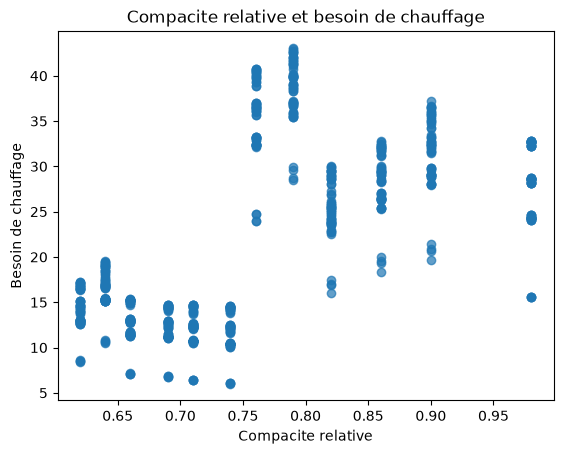

In [17]:
plt.scatter(df_energy['Relative_Compactness'], df_energy['Heating_Load'], alpha=0.7)
plt.xlabel('Compacite relative'); plt.ylabel('Besoin de chauffage')
plt.title('Compacite relative et besoin de chauffage')
plt.show()

In [18]:
X_train, X_test, y_train_heat, y_test_heat = train_test_split(
    X, y_heating, test_size=0.2, random_state=42)

modele_heat = LinearRegression()
modele_heat.fit(X_train, y_train_heat)
y_pred_heat = modele_heat.predict(X_test)

mse_heat = mean_squared_error(y_test_heat, y_pred_heat)
r2_heat = r2_score(y_test_heat, y_pred_heat)
print('MSE chauffage :', mse_heat)
print('R² chauffage :', r2_heat)

MSE chauffage : 9.153207645941675
R² chauffage : 0.9121846294352438


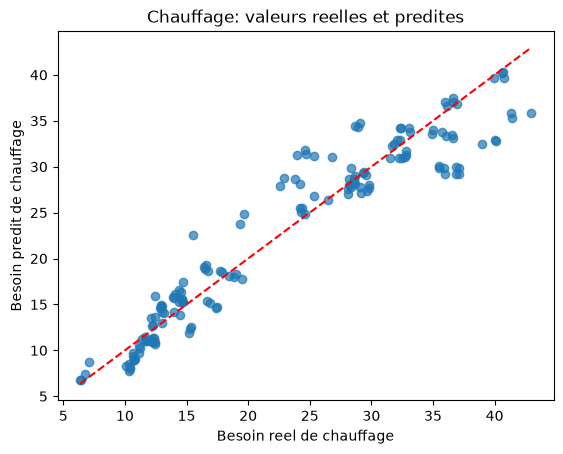

In [19]:
plt.scatter(y_test_heat, y_pred_heat, alpha=0.7)
minimum = min(y_test_heat.min(), y_pred_heat.min())
maximum = max(y_test_heat.max(), y_pred_heat.max())
plt.plot([minimum, maximum], [minimum, maximum], 'r--')
plt.xlabel('Besoin reel de chauffage'); plt.ylabel('Besoin predit de chauffage')
plt.title('Chauffage: valeurs reelles et predites')
plt.show()

In [20]:
X_train_cool, X_test_cool, y_train_cool, y_test_cool = train_test_split(
    X, y_cooling, test_size=0.2, random_state=42)

modele_cool = LinearRegression()
modele_cool.fit(X_train_cool, y_train_cool)
y_pred_cool = modele_cool.predict(X_test_cool)

mse_cool = mean_squared_error(y_test_cool, y_pred_cool)
r2_cool = r2_score(y_test_cool, y_pred_cool)
print('MSE refroidissement :', mse_cool)
print('R² refroidissement :', r2_cool)

MSE refroidissement : 9.893427647944062
R² refroidissement : 0.893225526860729


In [21]:
resultats = pd.DataFrame({
    'Cible': ['Heating Load', 'Cooling Load'],
    'MSE': [mse_heat, mse_cool],
    'R²': [r2_heat, r2_cool]
})
display(resultats)

,Cible,MSE,R²
0,Heating Load,9.153208,0.912185
1,Cooling Load,9.893428,0.893226
